# Phoenix autocall

Note 5 ans, 20 dates trimestrielles, coupon 2 % par date (8 % par an), rappel a
100 %, barriere de coupon a 70 %, protection europeenne a 60 %.
S = 100, r = 3 %, q = 1 %, sigma = 20 %.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent / "src"))

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import black_scholes as bs
import Monte_Carlo as mc
import barriere as br
import autocall as ac

## Paramètres de référence

In [2]:
S0, R0, Q0, V0, T0 = 100.0, 0.03, 0.01, 0.20, 5.0
N_OBS = 20

BASE = dict(r=R0, q=Q0, sigma=V0, T=T0, n_obs=N_OBS, n_sims=200_000, seed=0)
PROD = dict(coupon=0.02, niveau_rappel=1.0,
            barriere_coupon=0.7, barriere_protection=0.6)

dates = ac.dates_observation(T0, N_OBS)

## Caractéristiques du produit

In [3]:
res = ac.prix_autocall_mc(S0, **PROD, **BASE)

df = pd.Series({
    'Prix':res['prix'],
    'Erreur Standard':res['err_std'],
    'durée de vie moyenne':res['duree_vie_moyenne'],
    'proba survie à maturité':res['proba_survie_maturite'],
    'proba de perte':res['proba_perte'],
    'perte moyenne si perte':res['perte_moyenne_si_perte']
    }).to_frame('valeurs').round(4)

df

,valeurs
Prix,101.9449
Erreur Standard,0.0285
durée de vie moyenne,1.2581
proba survie à maturité,0.1292
proba de perte,0.0568
perte moyenne si perte,52.5344


**Analyse** : on constate que l'autocall, bien qu'ayant une maturité de 5 ans, à une espérance de vie bien plus faible en réalité (1,25 ans), et que la probabilité de survie durant les 5 année n'est que de 12,92%. 
2ème point : La proba de perte est faible (5,68%), mais s'il y a perte, alors celle-ci est très importante (52,53% du capital). C'est le concept même du produit, qui a été construit en ce sens

## Probabilite de rappel par date

1.0


Text(2.75, 0.890775, '87.1% rappelees avant maturite')

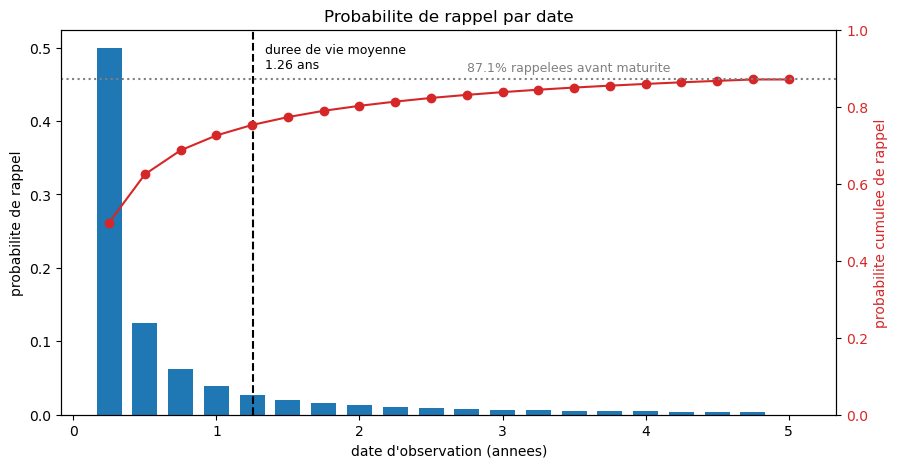

In [4]:
par_date = res["proba_rappel"].copy()
par_date[-1] = 0.0        # A la derniere date on ne rappel pas car on est à la maturité.

cumul = np.cumsum(par_date)
print(f'{cumul[-1]+res['proba_survie_maturite']}')          

fig, ax = plt.subplots(figsize=(10,5))
ax.bar(dates,par_date,width=0.7*T0/N_OBS)
ax.set_xlabel("date d'observation (annees)")
ax.set_ylabel("probabilite de rappel")
ax.set_title("Probabilite de rappel par date")


ax2 = ax.twinx()
ax2.plot(dates, cumul, color="tab:red", marker="o", label="cumul")
ax2.set_ylabel("probabilite cumulee de rappel", color="tab:red")
ax2.tick_params(axis="y", labelcolor="tab:red")
ax2.set_ylim(0, 1)
ax.set_title("Probabilite de rappel par date")


ax.axvline(res["duree_vie_moyenne"], color="black", linestyle="--", linewidth=1.5)
ax.text(res["duree_vie_moyenne"] + 0.08, ax.get_ylim()[1] * 0.9,
        f"duree de vie moyenne\n{res['duree_vie_moyenne']:.2f} ans",
        fontsize=9)

total_rappele = 1 - res["proba_survie_maturite"]
ax2.axhline(total_rappele, color="gray", linestyle=":", linewidth=1.5)
ax2.text(T0 * 0.55, total_rappele + 0.02,
         f"{total_rappele:.1%} rappelees avant maturite",
         fontsize=9, color="gray")


**Analyse** : la première date à 50% de chance d'être rappelé, et ensuite la proba par date diminue, car à chaque date on ne voit que les trajectoires survivantes de la date précédente

## Distribution de l'autocall

nombre des trajectoires étudiées : 200000


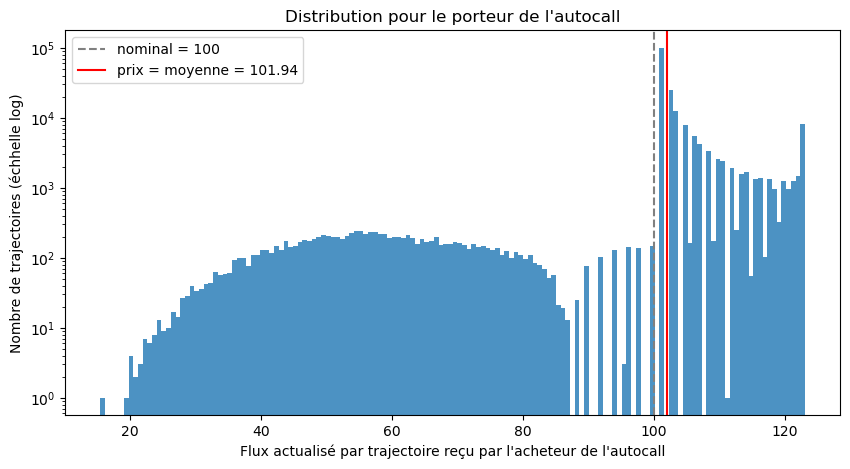

In [5]:
fig, ax3 = plt.subplots(figsize=(10,5))
ax3.hist(res["flux"],bins=150,alpha=0.8)
ax3.axvline(100,color="grey",ls='--',label='nominal = 100')
ax3.axvline(res["prix"],color='red',label=f'prix = moyenne = {res['prix']:.2f}')
plt.yscale("log")
plt.ylabel('Nombre de trajectoires (échhelle log)')
plt.xlabel("Flux actualisé par trajectoire reçu par l'acheteur de l'autocall")
plt.title("Distribution pour le porteur de l'autocall")
ax3.legend()
print(f'nombre des trajectoires étudiées : {BASE['n_sims']:.0f}')

**Analyse** : 
- Grand pic à 101.24 : sur 200 000 trajectoires ici, le scénario le plu probable, et de très loin (10^5 trajectoires = 50% des trajectoires) est le prix moyen autour de 101.24 : c'est le scénario où l'autocall est rappelé à la première date (nominal+1 coupon reçu). 
- Bande plate de 18 à 87 : C'est tous les scénarios où on a une perte en capital car barrière cassée à maturité, là où le put down-and-in s'active donc. Cette zone est continue car le nominal reçu à la fin dépend de S_T dans ce scénario (l'acheteur reçoit nominal*S_T/S0). On voit en revanche que la perte en capital est de proba faible (10^2 de trajectoires par barre en échelle log), mais que si il y a perte, celle ci peut être importante (bande très large)
- Le peigne discret entre 87 et 103 : Il s'agit des trajectoires qui gagent des coupons. Plus le rappel est tardif, plus le flux est évelvé ici. Les pics sont di.

## Sensibilite a la volatilite

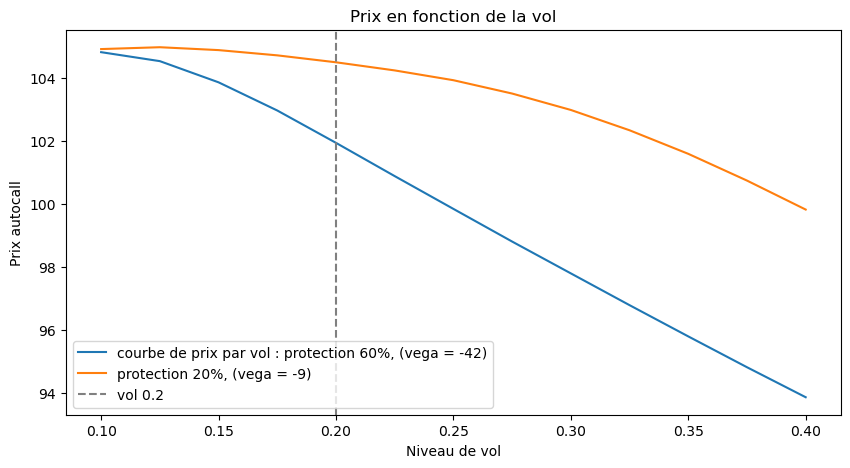

In [6]:
vols = np.linspace(0.10, 0.40, 13)
prix_vol = [ac.prix_autocall_mc(S0,**PROD,**{**BASE,'sigma':v})['prix'] for v in vols]

vega_20  = ac.vega_autocall(S0,**PROD,**BASE)
fig, ax4 = plt.subplots(figsize=(10,5))
ax4.plot(vols,prix_vol,label=f'courbe de prix par vol : protection 60%, (vega = {vega_20:.0f})')
plt.xlabel('Niveau de vol')
plt.ylabel('Prix autocall')
plt.title('Prix en fonction de la vol')

#Version avec barrière de protection abaissée pour comparer
vega_20_v2  = ac.vega_autocall(S0,**{**PROD,'barriere_protection':0.2},**BASE)
prix_vol = [ac.prix_autocall_mc(S0,**{**PROD,'barriere_protection':0.2},**{**BASE,'sigma':v})['prix'] for v in vols]
ax4.plot(vols,prix_vol,label=f'protection 20%, (vega = {vega_20_v2:.0f})')
plt.axvline(0.2,ls='--',color='grey',label='vol 0.2')

plt.legend()

**Analyse** : on voit ici que l'acheteur d'un call est bien vendeur d'un put-down-and-in : la conséquence est que il est short volatilité (de pente environ -0.42 par point de vol, ou -42 par unité de vol similairement).

De plus, on observe bien que une barrière de protection abaissée (donc moins de chance de perdre en activant le put) applitit signficativement la sensibilité du prix par rapport à la volatilité, car c'est moins dangereux.


## Prix en fonction du niveau de rappel

coupon pivot = 1.2650% par trimestre, soit 5.06% par an
pente a coupon 0 %   : -13.3931
pente a coupon 2 %   : +7.7821

coupon pivot = 1.2650% par trimestre, soit 5.060% par an   (15 iterations)
taux sans risque par trimestre : 0.7500%


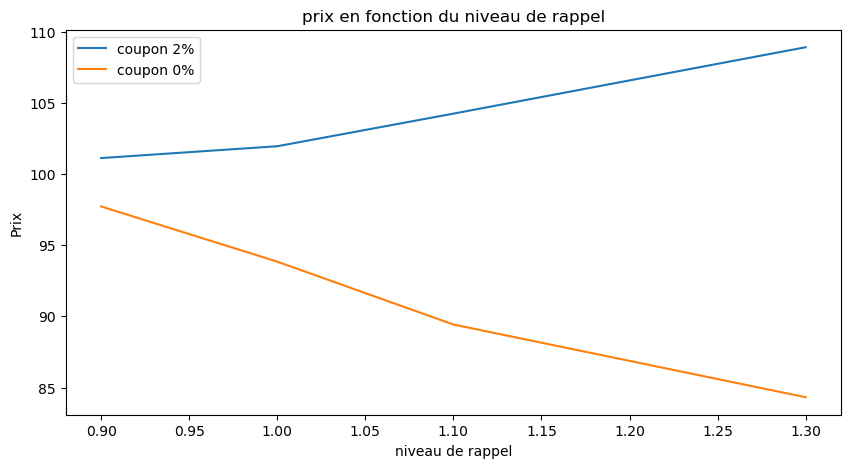

In [7]:
niveaux = (0.9, 1.0, 1.1, 1.3)
prix = [ac.prix_autocall_mc(S0,**BASE,**{**PROD,'niveau_rappel':n})['prix'] for n in niveaux]
prix_0 = [ac.prix_autocall_mc(S0,**BASE,**{**PROD,'coupon':0.0,'niveau_rappel':n})['prix'] for n in niveaux]

fig, ax5 = plt.subplots(figsize=(10,5))
ax5.plot(niveaux,prix,label='coupon 2%')
ax5.plot(niveaux,prix_0,label='coupon 0%')
plt.title('prix en fonction du niveau de rappel')
plt.xlabel('niveau de rappel')
plt.ylabel('Prix')
plt.legend()

#Coupon pivot
DEFAUT = {**PROD, **BASE}
def prix(**surcharges):
    return ac.prix_autocall_mc(S0, **{**DEFAUT, **surcharges})['prix']

def pente(c):
    return prix(coupon=c, niveau_rappel=1.3) - prix(coupon=c, niveau_rappel=0.9)

f0, f2 = pente(0.0), pente(0.02)
coupon_pivot = -f0 * 0.02 / (f2 - f0)

print(f"coupon pivot = {coupon_pivot:.4%} par trimestre, soit {4*coupon_pivot:.2%} par an")

# 1. Encadrement avant dichotomie
a, b = 0.0, 0.02
f_a, f_b = pente(a), pente(b)
print(f"pente a coupon 0 %   : {f_a:+.4f}")
print(f"pente a coupon 2 %   : {f_b:+.4f}")
assert f_a * f_b < 0, "pas de changement de signe : elargis l'intervalle"

# 2. Dichotomie
for k in range(30):
    m = 0.5 * (a + b)
    f_m = pente(m)
    if f_a * f_m > 0:
        a, f_a = m, f_m
    else:
        b, f_b = m, f_m
    if b - a < 1e-6:
        break

coupon_pivot = 0.5 * (a + b)
print(f"\ncoupon pivot = {coupon_pivot:.4%} par trimestre, "
      f"soit {4*coupon_pivot:.3%} par an   ({k+1} iterations)")
print(f"taux sans risque par trimestre : {BASE['r']*BASE['T']/BASE['n_obs']:.4%}")

**Analyse** : on constate que on a 2 effets qui s'oppose quand on rend le rappel plus difficile : rester vivant permet d'avoir plus de coupons (prix à la hausse), mais ça nous expose aussi plus longtemps à la barrière de protection (prix à la baisse) et repousse aussi le remboursement du nominal (prix à la baisse). Et l'arbitrage à faire sur le niveau de rappel par rapport à tout ça dépend entièrement du coupon.

- à 2%, le coupon est suffisamment elevé pour l'emporter : le prix monte
- à 0%, le prix dminimue evidemment
- Par dichotomie, on trouve que le coupon qui égalise ces 3 effets d'une augmentation de la barrière de rappel (plus de coupons, plus longtemps exposé à put- down-and-in, actualisation sur nomial plus forte) est ici dans cet exemple de 1,26% (par trimestre).

## Tests impact mémoire / impact du type de protection (europenne/continue)

impact de la mémoire :  0.0086 point de nominal


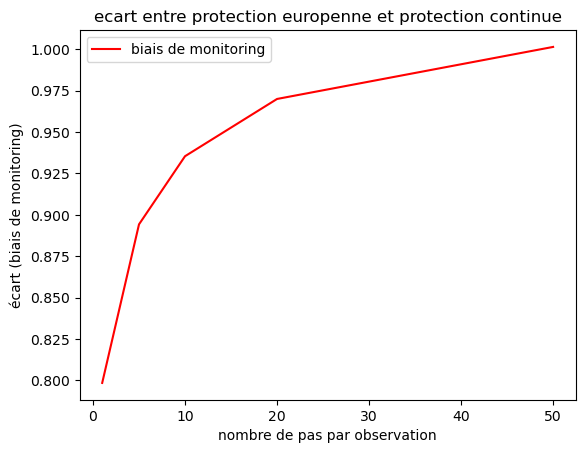

In [8]:
#Test memoire
avec_memoire = ac.prix_autocall_mc(S0,**BASE,**PROD)['prix']
sans_memoire = ac.prix_autocall_mc(S0,**BASE,**{**PROD,'memoire':False})['prix']
diff = (avec_memoire - sans_memoire)/100
print(f"impact de la mémoire :  {diff:.4f} point de nominal")

#Test protection
liste_pas = [1,5,10,20,50]
diffs = []
for p in liste_pas:
    prot_europeenne = ac.prix_autocall_mc(S0,**BASE,**PROD)['prix']
    prot_continue = ac.prix_autocall_mc(S0,n_pas_par_obs=p,protection='continue',**BASE,**PROD)['prix']
    diffs.append(prot_europeenne-prot_continue)
diffs = np.asarray(diffs)
plt.plot(liste_pas,diffs,label='biais de monitoring',color='red')
plt.xlabel('nombre de pas par observation')
plt.ylabel('écart (biais de monitoring)')
plt.title('ecart entre protection europenne et protection continue')
plt.legend()
plt.show()


**Analyse** : on observe que la protection continue est systématiquement plus basse en prix que la protection européenne (plus facile à casser donc vaut moins, même à 1 pas par observation la différence est de 0.8 point de nominal (car les conditions de cassage de la barrière changent même si on regarde aux même dates)). Néanmoins, il plafonne assez vite à vers 1 (point de nominal), l'essentiel du biais de monitoring se fait dans les 20 premiers nombre de pas par observation.

## Delta de l'autocall et variation


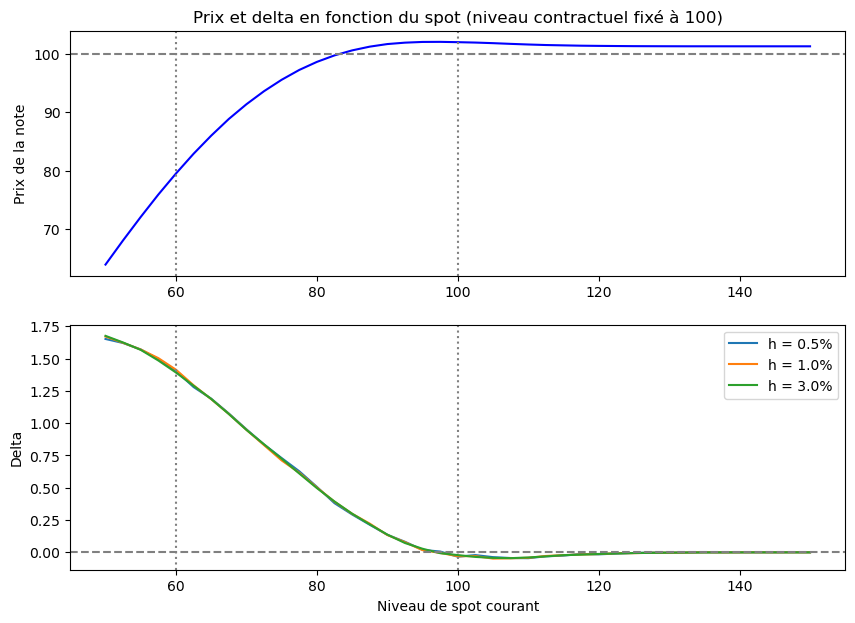

In [9]:
S_REF = 100.0
spots = np.arange(50.0, 150.1, 2.5)

def prix_spot(S, **surcharges):
    return ac.prix_autocall_mc(S, **{**DEFAUT, 'S_ref': S_REF, **surcharges})['prix']

def delta_spot(S, h_rel=0.01, **surcharges):
    h = S * h_rel
    return (prix_spot(S + h, **surcharges) - prix_spot(S - h, **surcharges)) / (2 * h)

prix2 = [prix_spot(s) for s in spots]
deltas = {hr: [delta_spot(s, h_rel=hr) for s in spots]
          for hr in (0.005, 0.01, 0.03)}

plt.figure(figsize=(10, 7))

plt.subplot(2, 1, 1)
plt.plot(spots, prix2, color='blue')
plt.axhline(100, ls='--', color='grey')
plt.axvline(100, ls=':', color='grey')
plt.axvline(60, ls=':', color='grey')
plt.ylabel('Prix de la note')
plt.title('Prix et delta en fonction du spot (niveau contractuel fixé à 100)')

plt.subplot(2, 1, 2)
for hr in (0.005, 0.01, 0.03):
    plt.plot(spots, deltas[hr], label=f'h = {hr:.1%}')
plt.axhline(0, ls='--', color='grey')
plt.axvline(100, ls=':', color='grey')
plt.axvline(60, ls=':', color='grey')
plt.xlabel('Niveau de spot courant')
plt.ylabel('Delta')
plt.legend()

plt.show()

**Analyse** : 
- loin en dessous le put vendu domine et la note suit le sous-jacent (en delta et en prix)
- autour du niveau de rappel le delta passe négatif (et donc le prix de la note à son maximum en ce point), parce qu'une hausse rend le rappel plus probable et coupe les coupons futurs
- tres au-dessus la note est un remboursement quasi certain et ne reagit plus (on est dans le scénario (nominal+un coupon, actualisé à 1 trimestre)

## Tirages communs indispensables


moyenne delta à tirages communs :     0.49
moyenne delta à tirages indépendants :  0.49
ecart-type à tirage communs :          0.02586
ecart-type à tirage indépendants :     0.24629
rapport d'écart-type :                 9.52
rapport de variance :                  90.69


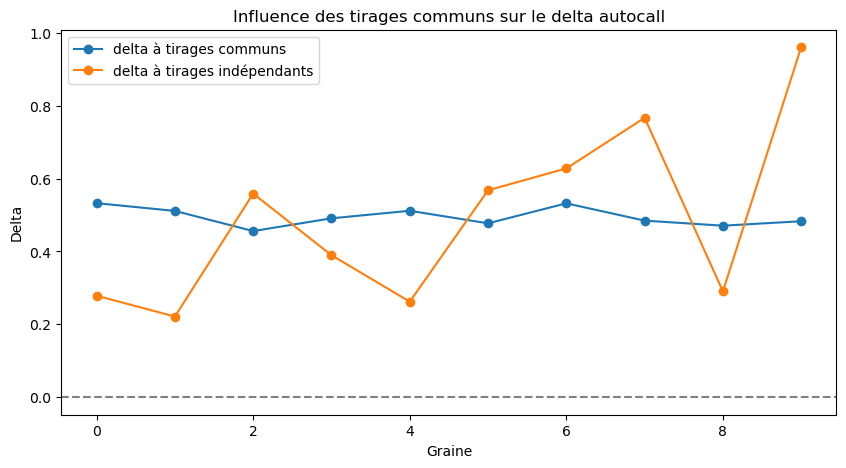

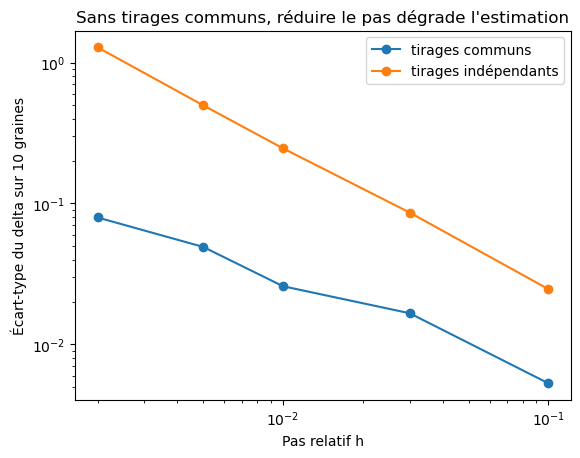

pente log-log : indépendants -1.00, communs -0.68


In [10]:
graines = range(10)
spot = 80
n_sims = 20000

def etude(h_test):
    communs,independants = [], []
    for g in graines:
        reglages = {**BASE, 'seed': g, 'n_sims': n_sims}
        communs.append(ac.delta_autocall(spot, S_ref=S_REF, h_reel=h_test,**reglages,**PROD))
        independants.append(ac.delta_autocall_graine_differente(spot, S_ref=S_REF, h_reel=h_test, **reglages,**PROD))
    return np.asarray(communs), np.asarray(independants)

#Première comparaison avec un pas de 1%
communs, independants = etude(0.01)
moyenne_commun = np.mean(communs)
ecart_commun = np.std(communs,ddof=1)
erreur_std_commun = ecart_commun/np.sqrt(len(communs))
moyenne_ind = np.mean(independants)
ecart_ind = np.std(independants,ddof=1)
erreur_std_ind = ecart_ind/np.sqrt(len(independants))
print(f"\nmoyenne delta à tirages communs :     {moyenne_commun:.2f}")
print(f"moyenne delta à tirages indépendants :  {moyenne_ind:.2f}")
print(f"ecart-type à tirage communs :          {ecart_commun:.5f}")
print(f"ecart-type à tirage indépendants :     {ecart_ind:.5f}")
print(f"rapport d'écart-type :                 {ecart_ind/ecart_commun:.2f}")
print(f"rapport de variance :                  {(ecart_ind/ecart_commun)**2:.2f}")
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(graines,communs,label='delta à tirages communs',marker='o')
ax.plot(graines,independants,label='delta à tirages indépendants',marker='o')
plt.axhline(0.0,color='grey',ls='--')
plt.xlabel('Graine')
plt.ylabel('Delta')
plt.title('Influence des tirages communs sur le delta autocall')
plt.legend()
plt.show()



#Etude du bruit en fonction du pas
pas = [0.002, 0.005, 0.01, 0.03, 0.10]
std_communs, std_ind = [],[]
for p in pas:
    c, i = etude(p)
    std_communs.append(c.std(ddof=1))
    std_ind.append(i.std(ddof=1))

plt.loglog(pas,std_communs,marker='o',label='tirages communs')
plt.loglog(pas,std_ind,marker='o',label='tirages indépendants')
plt.xlabel('Pas relatif h')
plt.ylabel('Écart-type du delta sur 10 graines')
plt.title("Sans tirages communs, réduire le pas dégrade l'estimation")
plt.legend()
plt.show()

pente_ind = np.polyfit(np.log(pas), np.log(std_ind), 1)[0]
pente_com = np.polyfit(np.log(pas), np.log(std_communs), 1)[0]
print(f"pente log-log : indépendants {pente_ind:.2f}, communs {pente_com:.2f}")

**Analyse** : On confirme dans le 1er graphique que sans tirages communs, les résultats sont quasi inexploitables, avec une variance multipliée par près de 90. C'est d'autant plus problématique qu'on a pas de modèle de référence pour l'autocall.

Ensuite, sur le 2ème graphique, on observe un résultat qu'on avait déjà remarqué dans notre fichier sur l'option barrière Put Down-and-in, c'est-à-dire que réduire le pas ne permet pas d'avoir de meilleurs résultats sans tirages communs (le bruit augmente en 1/h sans tirages communs, et en 1/np.sqrt(h) avec tirages communs)

## Variable de contrôle sur l'autocall

au paramétrage de référence (rappel 100 %) :
  erreur standard sans contrôle : 0.0285
  erreur standard avec contrôle : 0.0227
  corrélation                   : -0.6072
  facteur de réduction          : 1.58


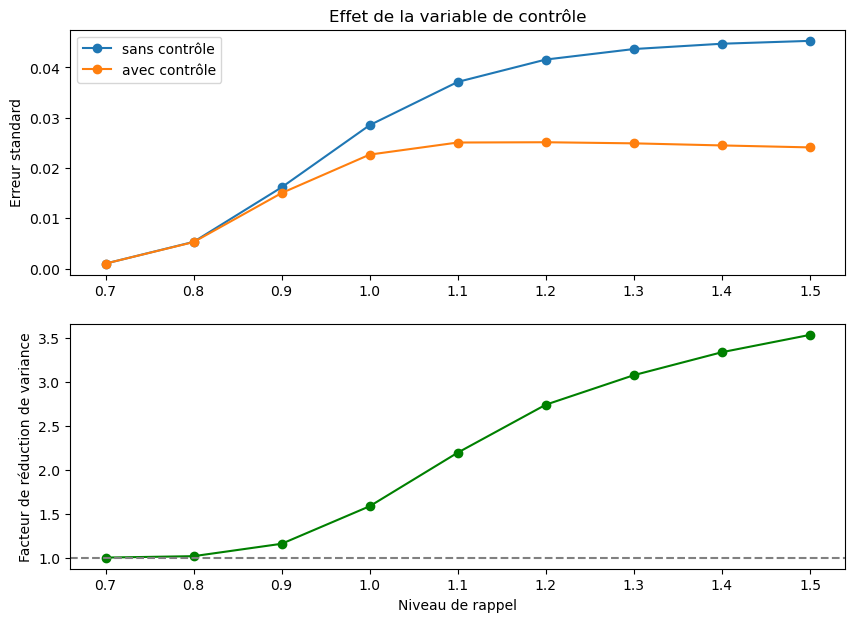

In [11]:
# TODO : facteur de reduction mesure, au parametrage de reference
# TODO : le faire varier avec le niveau de rappel (0.8 a 1.5)
#   Le gain doit s'effondrer quand le rappel est facile : explique pourquoi.
niveau_rappel = np.round(np.arange(0.7,1.6,0.1),2)
prix_ac, err_sc, err_ac, facteurs, correls = [], [], [], [], []
for n in niveau_rappel:
    appel = ac.prix_autocall_mc_controle(S0,**BASE,**{**PROD,'niveau_rappel':n})
    prix_ac.append(appel['prix'])
    err_sc.append(appel['err_std_simple'])
    err_ac.append(appel['err_std'])
    facteurs.append(appel['facteur_reduction'])
    correls.append(appel['correlation'])

i_ref = list(niveau_rappel).index(1.0)
print(f"au paramétrage de référence (rappel 100 %) :")
print(f"  erreur standard sans contrôle : {err_sc[i_ref]:.4f}")
print(f"  erreur standard avec contrôle : {err_ac[i_ref]:.4f}")
print(f"  corrélation                   : {correls[i_ref]:.4f}")
print(f"  facteur de réduction          : {facteurs[i_ref]:.2f}")


plt.figure(figsize=(10,7))
plt.subplot(2,1,1)
plt.plot(niveau_rappel, err_sc, marker='o', label='sans contrôle')
plt.plot(niveau_rappel, err_ac, marker='o', label='avec contrôle')
plt.ylabel('Erreur standard')
plt.title('Effet de la variable de contrôle')
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(niveau_rappel, facteurs, marker='o', color='green')
plt.axhline(1, ls='--', color='grey')
plt.ylabel('Facteur de réduction de variance')
plt.xlabel('Niveau de rappel')

plt.show()


**Analyse** : 
- Le contrôle plafonne l'erreur standard : sans contrôle, on observe que continue de monter à plus de 0.04 erreur standard au fur et à mesure que le niveau de rappel augmente (qui s'explique par le fait que quand le rappel est difficile, la courbe de distribution s'étale à tous les scénarios possibles, et donc la dispertion explose). En revanche, on observe que avec le contrôle, cette dispertion est limité / plafonnée à environ 0.025. 

- Facteur de réduction de variance : On observe que la varible de contrôle permet effectivement de limiter la variance (d'un facteur 1 à 3.5 environ). Cependant, Il n'est que de 1.6 graphiquement (on le retrouve avec la formule de la corrélation : 1/(1-0,607²) = 1.58 avec les données trouvées ci-dessus) au paramétrage de référence rappel à 100%, ce qui est modeste. On observe surtout que son efficacité dépend surtout du niveau de rappel : plus le niveau de rappel est haut, plus la réduction de variance est efficace. Cela s'explique par le fait que le contrôle se fait sur un put vanille sur S_T (qui ne voit pas le chemin parcouru donc), donc quand le rappel est facile (bas), ce qui différencie une trajectoire d'une autre est la date à laquelle elle meurt, or le put de contrôle ne dit rien sur cette date donc ne corrige rien. AU contraire, quand le rappel est plus difficile (barrière rappel plus haute), alors davantage de trajectoires survivent à maturité, et donc la variance provient davantage de la partie optionnel et donc le contrôle redevient pertinent. 


## Limite du pricer autocall

- **La volatilite est constante** : La volatilité est supposé constante dans ce modèle (comme BS), alors que le payoff vit dans la queue gauche ou le skew actions est le plus pentu
- **pricer d'autocall primaire uniquement ici**, : Pas possible de pricer au spot courant avec ce pricer (en l'état), des autocall qui ont été émis dans le passé. Il faudra rajouter d'autres features pour cela
- **biais de monitoring sur la protection continue** : Quand le contrat de la barrière est européen, ça pose pas de problème car les dates d'observations sont les mêmes que celles du contrat, mais quand la protectione st continue il y a forcément un biais (version continue sous-évaluée), et la correction de Broadie-Glasserman-Kou n'est pas appliqué ici
- **pin risk non mesure ici** : le gamma au voisinage du niveau de rappel juste avant une date d'observation n'est pas mesuré ici, alors qu'il s'agit d'un risque important pour un desk